In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM

/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [2]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
import copy
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [3]:
directory_path = '/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

460


In [4]:
eid = eids[18]

In [5]:
#########################################################################
###################### Generate response matrix for eid #################
#########################################################################

full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")

# for _ in range(1):

dim = 5
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "stimOn_times"
clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

counts_series = clusters.groupby('cosmos').size()
print(counts_series)

# shape n_pseudo x n_conditions x time x n
response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
spikes, clusters, trials, event, conditions,
stride=.005,
step=.005,
n_steps=n_steps,
sigma=sigma,
threshold=threshold,
min_trials_per_condition=min_trials_per_condition,regions = counts_series.index.values )

# Restrict to active units
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                         np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
response_matrix_train = response_matrix_train[
:, :, :, restriction]


Randomly selected eid: /Users/cl1704/PycharmProjects/embedding_dimension/BWM/Data2/ff4187b5-4176-4e39-8894-53a24b7cf36b
cosmos
CNU          947
CTXsp        124
Isocortex    532
OLF          155
root         321
dtype: int64


In [6]:
N_NEURONS  = response_matrix_train.shape[3]
data = np.mean(response_matrix_train, axis = 0)
data = (data - np.mean(data, axis=(0, 1),keepdims=True)) / np.std(data,
                                                                              axis=(0, 1),
                                                                              keepdims=True)
data_snr = []
for neuron in range(N_NEURONS):
    means = []
    for t in range(99):
        h = (data[:, t + 1, neuron] - data[:, t, neuron]) / (data[:, t, neuron] + 5)
        means.append(np.mean(np.abs(h)))
    data_snr.append(np.mean(means))
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
#data =np.mean(data, axis = 0)

data = data.reshape(-1, data.shape[2])

In [8]:
def calculate_gain(rnn,conditions,steps,epsilon):

        # Simulate RNN
        x = rnn.forward(conditions,steps)

        # Z-score
       # x = (x - torch.mean(x, dim=(0, 1))) / torch.std(x,dim=(0, 1))
        h = torch.abs(torch.diff(x,dim=1)/(x[:,:-1,:]+epsilon))
        g = torch.mean(h,dim=(0,1))
        return g

In [15]:
# Train RNN to reproduce gains.
#########################################################################
########################### Fit RNN to data  ############################
#########################################################################

conditions = torch.FloatTensor(np.linspace(-1,1,20))[:,None]
rnn = RNN(n = data.shape[1], input_dim = 5, n_conditions = conditions.shape[1],beta=10,sigma_rec=0.)



In [20]:
epochs  = 1000
steps = 100

optimizer = torch.optim.Adam(rnn.parameters(), lr=.001, weight_decay=0.001)

epoch = 0
while epoch < epochs:


    optimizer.zero_grad()

    g = calculate_gain(rnn,conditions,steps,epsilon = 10)
    gain_loss  = torch.nn.MSELoss()(g[:rnn.n], torch.FloatTensor(data_snr))

    # Compute mean squared error for each neuron normalized by the variance in that neuron
    loss = 100*gain_loss

    loss.backward()
    optimizer.step()
    #self.recurrent_layer.bias.data = torch.nn.ReLU()(self.recurrent_layer.bias.data)
    #self.alpha.data = torch.nn.Softplus()(self.alpha.data)
    epoch += 1


    if epoch % 10 == 0:

        print('Epoch: {}/{}.............'.format(epoch, epochs), end=' ')
        print("loss: {:.4f}".format(loss.item()))
            #writer.
            #add_scalar('Loss/test', loss.item(), epoch)

Epoch: 10/1000............. loss: 0.0179
Epoch: 20/1000............. loss: 0.2941
Epoch: 30/1000............. loss: 0.0748
Epoch: 40/1000............. loss: 24.3913
Epoch: 50/1000............. loss: 146.5522
Epoch: 60/1000............. loss: 5.0051
Epoch: 70/1000............. loss: 389.3049
Epoch: 80/1000............. loss: 12.0515
Epoch: 90/1000............. loss: 75.9894
Epoch: 100/1000............. loss: 16.2507
Epoch: 110/1000............. loss: 11.7150
Epoch: 120/1000............. loss: 13.1841
Epoch: 130/1000............. loss: 130.1562


KeyboardInterrupt: 

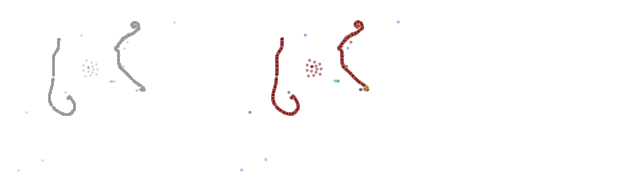

In [21]:
####################################################################
#################### DensMap plot for fit RNN ######################
####################################################################

from sklearn.manifold import TSNE
#g = perturbed_rnn.calculate_gain(condition_train,100,20).detach()


x = rnn(conditions,100).detach()
x = x[:,:,:rnn.n]
x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))
#x = x  + 2*(2*torch.rand_like(x)-1)

x = x.detach().numpy()
g =  calculate_gain(rnn,conditions,steps,10).detach()
# g = []
# for neuron in range(N_NEURONS):
#     means = []
#     for t in range(99):
#         h = (x[:, t + 1, neuron] - x[:, t, neuron]) / (x[:, t, neuron] + 20)
#         means.append(np.mean(np.abs(h)))
#     g.append(np.mean(means))


#x_proj  = PCA(n_components = 2).fit_transform(responses.T)
#x_proj  = TSNE(n_components = 2,perplexity = 800).fit_transform(x.reshape(-1,x.shape[2]).T)
#x_proj  = TSNE(n_components = 2,perplexity = 200).fit_transform(x.reshape(-1,x.shape[2]).T)
fit = umap.UMAP(n_components = 2,densmap = True, dens_lambda =1 ,n_neighbors = 800)
x_proj= fit.fit_transform(x.reshape(-1,x.shape[2]).T)
#x_proj = projection_model(torch.FloatTensor(x.reshape(-1,x.shape[2]).T)).detach().numpy()
#pca = PCA(n_components=2).fit(x.reshape(-1,x.shape[2]).T)
#x_proj = pca.transform(x.reshape(-1,x.shape[2]).T)
fig = plt.figure(figsize=(8,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,3,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=3,ax=ax0,color='gray',alpha = .35,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)

sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=5,hue =g[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo',hue_norm=(.001,.01))

#sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=3,hue =mag[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo')
for ax in [ax0,ax1,ax2]:
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_.jpg')


In [11]:
g

tensor([0.0011, 0.0011, 0.0010,  ..., 0.0011, 0.0010, 0.0010])

<Axes: xlabel='None'>

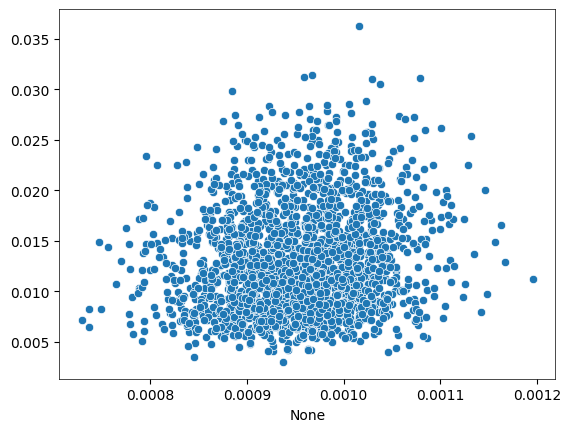

In [19]:
plt.figure()
sns.scatterplot(x=g[:rnn.n], y = data_snr)